# 09 · Bayesian hyperparameter optimisation (LightGBM, Optuna TPE)
Objective: mean macro F1 over 3-fold GroupKFold on train trips. Student-test is only used afterwards.

In [1]:
import sys, os, json, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pathsnap").is_dir()), None)
if _root is None:
    raise RuntimeError("src/pathsnap not found: unzip all zips of the set into the same pathsnap/ folder")
sys.path.insert(0, str(_root / "src")); os.chdir(_root / "notebooks")
import optuna, pandas as pd, matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from pathsnap import modeling

S = modeling.SEED
tr, te = modeling.load_tables()
optuna.logging.set_verbosity(optuna.logging.WARNING)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def make(p):
    return LGBMClassifier(**p, subsample_freq=1, random_state=S, verbose=-1)

def objective(trial):
    p = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 15, 127, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 200, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    )
    cv, _ = modeling.cross_validate(make(p), tr, folds=3)
    trial.set_user_attr("cv_top1", cv.top1_acc.mean())
    return cv.macro_f1.mean()

t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=S))
study.enqueue_trial(dict(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=20,
                         subsample=0.8, colsample_bytree=0.8, reg_lambda=1e-3))
study.optimize(objective, n_trials=25)
bo_time = time.time() - t0
trials = study.trials_dataframe()
trials.to_csv("../outputs/bo_trials.csv", index=False)
json.dump(dict(best_params=study.best_params, best_cv_macro_f1=study.best_value, n_trials=len(trials),
               search_seconds=bo_time), open("../outputs/bo_best.json", "w"), indent=2)
print(study.best_params, round(study.best_value, 4), f"{bo_time / 60:.1f} min")

{'n_estimators': 800, 'learning_rate': 0.05653381629760746, 'num_leaves': 18, 'min_child_samples': 13, 'subsample': 0.9198870986647855, 'colsample_bytree': 0.7738839201893054, 'reg_lambda': 0.020089366106018892} 0.936 6.0 min


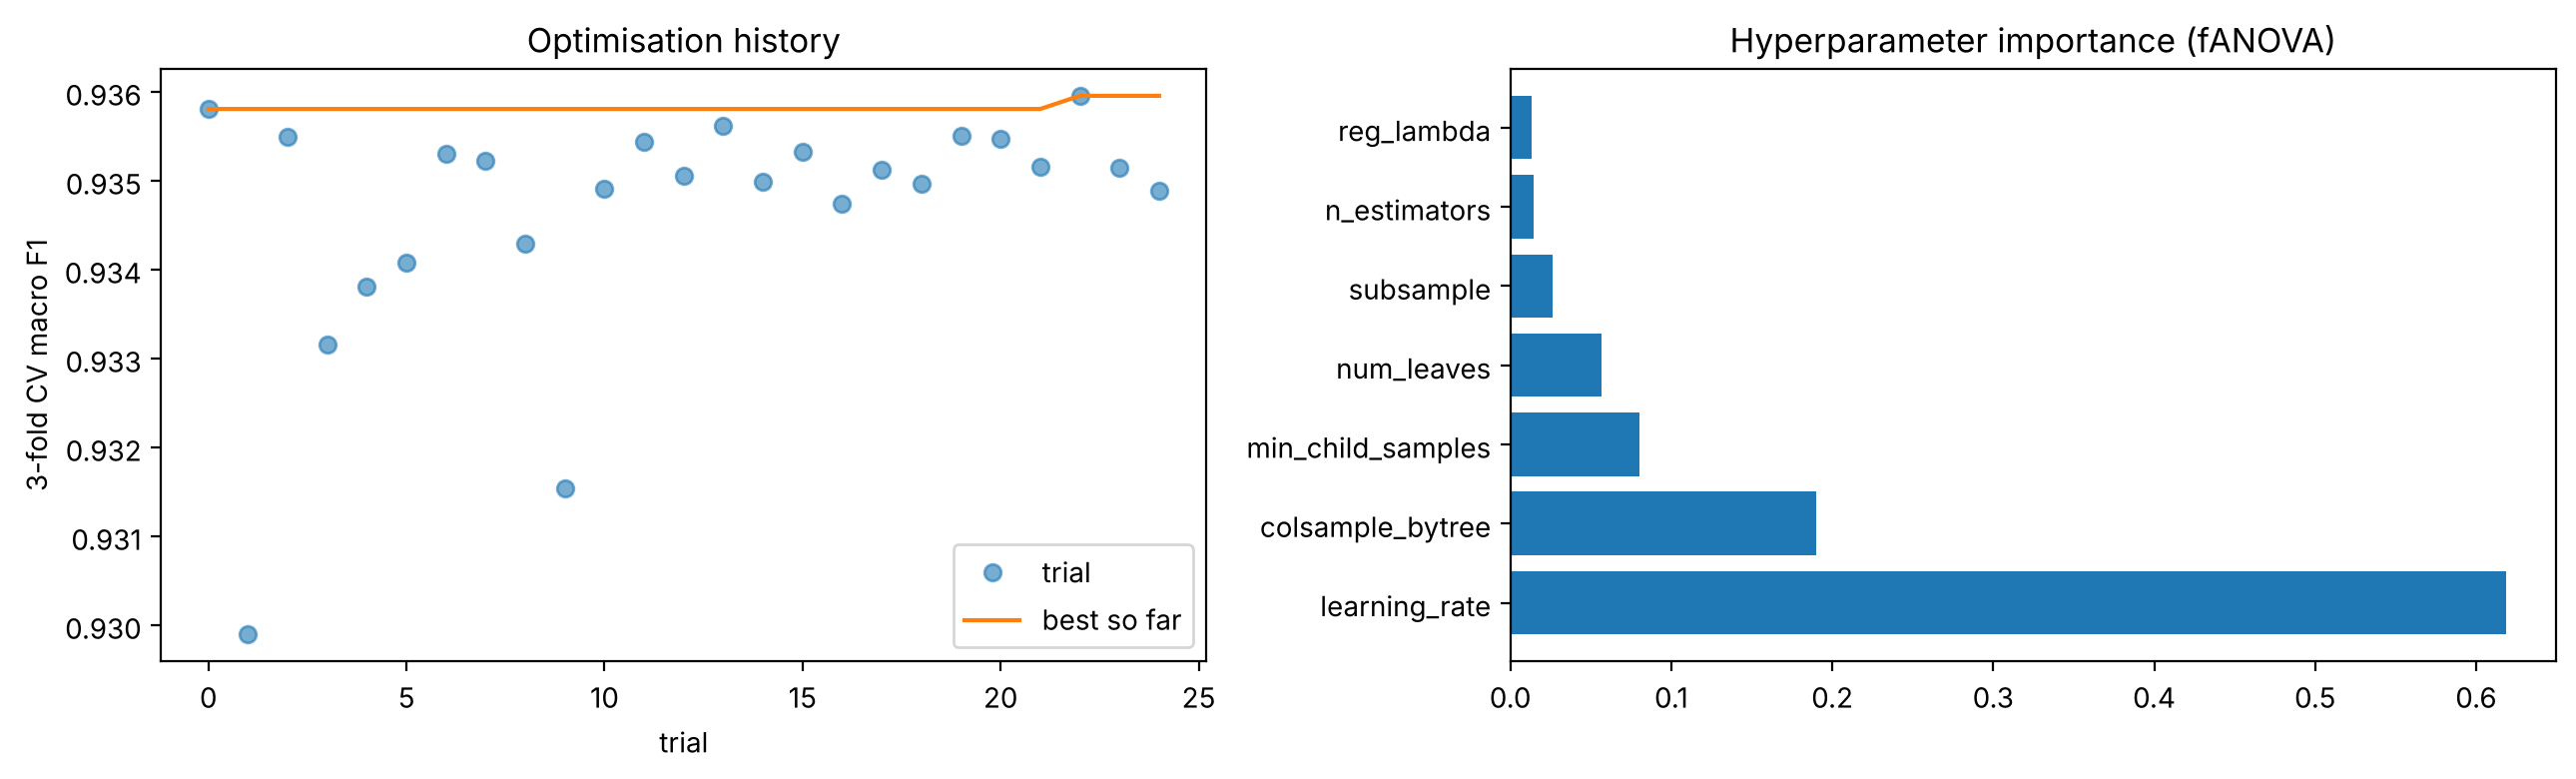

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(trials.number, trials.value, "o", alpha=.6, label="trial")
ax[0].plot(trials.number, trials.value.cummax(), label="best so far")
ax[0].set_xlabel("trial"); ax[0].set_ylabel("3-fold CV macro F1"); ax[0].legend(); ax[0].set_title("Optimisation history")
imp = optuna.importance.get_param_importances(study)
ax[1].barh(list(imp), list(imp.values())); ax[1].set_title("Hyperparameter importance (fANOVA)")
plt.tight_layout(); plt.savefig("../outputs/figures/bo_history.png", dpi=120)

In [4]:
tuned, model, _ = modeling.run("M6_lightgbm_tuned", "Boosting", json.dumps(study.best_params), make(study.best_params), tr, te)
untuned = json.load(open("../outputs/models/M6_lightgbm.json"))
keys = ["cv_macro_f1", "test_top1_acc", "test_macro_f1", "test_log_loss", "test_route_continuity", "infer_ms_per_point"]
cmp = pd.DataFrame({"untuned": [untuned[k] for k in keys], "tuned": [tuned[k] for k in keys]}, index=keys)
cmp.to_csv("../outputs/bo_tuned_vs_untuned.csv")
cmp.round(4)

,untuned,tuned
cv_macro_f1,0.9356,0.9354
test_top1_acc,0.8875,0.8879
test_macro_f1,0.9351,0.9353
test_log_loss,0.0833,0.0833
test_route_continuity,0.7531,0.7540
infer_ms_per_point,0.0676,0.1082
